In [11]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [3]:
data = pd.read_csv("healthcare_patient_dataset_1000.csv")
data

,Patient_ID,Age,Gender,BMI,Systolic_BP,Diastolic_BP,Glucose_Level,Cholesterol,Heart_Rate,Physical_Activity_Hours_Per_Week
0,P0001,55,Female,35.2,148,88,141,246,88,0.9
1,P0002,62,Male,26.9,112,87,126,161,80,3.6
2,P0003,68,Male,33.8,124,94,135,219,91,3.1
3,P0004,64,Female,28.1,136,90,118,214,86,2.7
4,P0005,20,Female,21.3,118,72,96,191,69,5.0
...,...,...,...,...,...,...,...,...,...,...
995,P0996,46,Male,22.2,153,70,93,223,72,1.1
996,P0997,73,Male,24.5,129,82,131,224,69,2.4
997,P0998,35,Male,19.0,132,66,91,146,61,3.3
998,P0999,53,Female,29.1,131,97,121,204,77,2.7


In [4]:
x = data[['Age', 'BMI', 'Glucose_Level', 'Cholesterol']]
x

,Age,BMI,Glucose_Level,Cholesterol
0,55,35.2,141,246
1,62,26.9,126,161
2,68,33.8,135,219
3,64,28.1,118,214
4,20,21.3,96,191
...,...,...,...,...
995,46,22.2,93,223
996,73,24.5,131,224
997,35,19.0,91,146
998,53,29.1,121,204


In [5]:
x = x.dropna()

In [6]:
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

In [7]:
model = KMeans(n_clusters=3, random_state=42)
labels = model.fit_predict(x_scaled)

data = data.loc[x.index].copy()
data['Cluster'] = labels

print(data[['Patient_ID', 'Age', 'BMI', 'Cluster']].head(10))

  Patient_ID  Age   BMI  Cluster
0      P0001   55  35.2        1
1      P0002   62  26.9        0
2      P0003   68  33.8        1
3      P0004   64  28.1        0
4      P0005   20  21.3        2
5      P0006   50  37.5        0
6      P0007   60  33.8        1
7      P0008   64  31.0        1
8      P0009   27  25.5        2
9      P0010   39  25.1        0


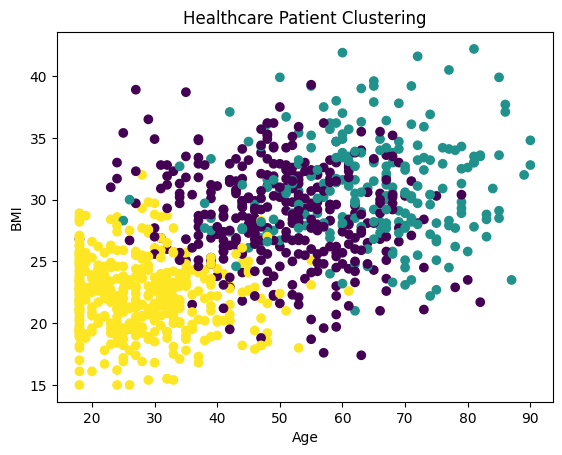

In [8]:
plt.scatter(x['Age'], x['BMI'], c=labels, cmap='viridis')

plt.xlabel('Age')
plt.ylabel('BMI')
plt.title('Healthcare Patient Clustering')

plt.show()

In [13]:
print(data['Cluster'].value_counts())

Cluster
2    416
0    360
1    224
Name: count, dtype: int64


In [17]:
data.to_csv('Healthcare_Cluster_Output.csv', index=False)
print(data.to_csv)

<bound method NDFrame.to_csv of     Patient_ID  Age  Gender   BMI  Systolic_BP  Diastolic_BP  Glucose_Level  \
0        P0001   55  Female  35.2          148            88            141   
1        P0002   62    Male  26.9          112            87            126   
2        P0003   68    Male  33.8          124            94            135   
3        P0004   64  Female  28.1          136            90            118   
4        P0005   20  Female  21.3          118            72             96   
..         ...  ...     ...   ...          ...           ...            ...   
995      P0996   46    Male  22.2          153            70             93   
996      P0997   73    Male  24.5          129            82            131   
997      P0998   35    Male  19.0          132            66             91   
998      P0999   53  Female  29.1          131            97            121   
999      P1000   27    Male  18.2          100            63            107   

     Cholesterol  H